<a href="https://colab.research.google.com/github/Angelinat3/IP-CV_odd-Angelina-Thennessa-Jo-3/blob/main/Pertemuan7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
from google.colab import drive

drive.mount("/content/drive")
folder_path = "/content/drive/MyDrive/PCVK/Images"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [17]:
def convolution2d(image, kernel, stride, padding):
  img = np.pad(image.astype(np.float64), padding)
  k = kernel.astype(np.float64)
  kh, kw = k.shape

  out_h = (img.shape[0] - kh) // stride + 1
  out_w = (img.shape[1] - kw) // stride + 1
  output = np.zeros((out_h, out_w), dtype=np.float64)

  for y in range(out_h):
    for x in range(out_w):
      y_start = y * stride
      x_start = x * stride
      patch = img[y_start : y_start + kh, x_start : x_start + kw]
      output[y, x] = np.sum(patch * k)

  return np.clip(output, 0, 255).astype(np.uint8)

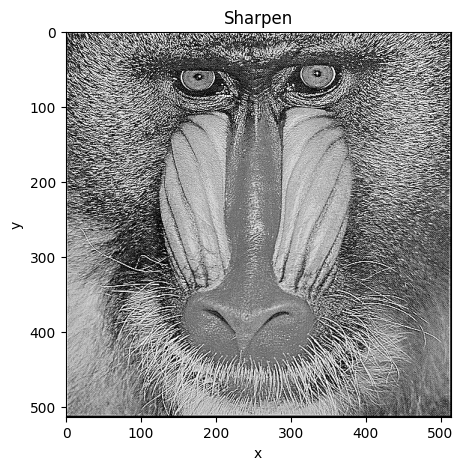

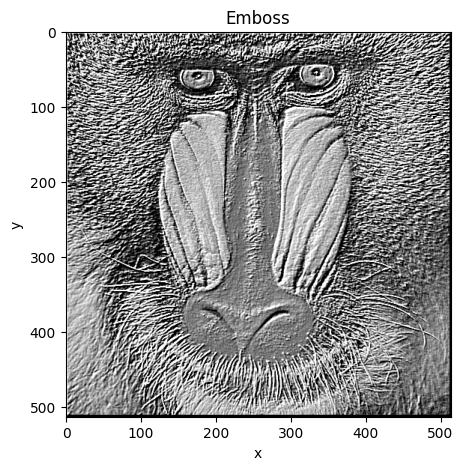

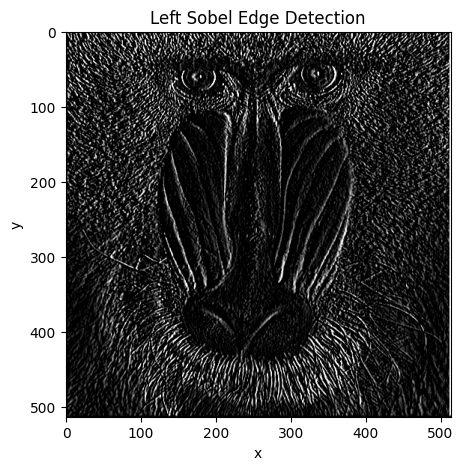

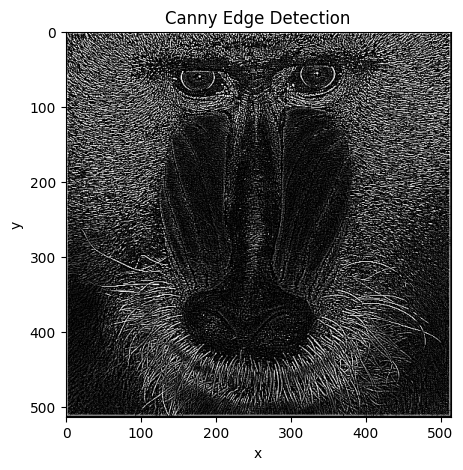

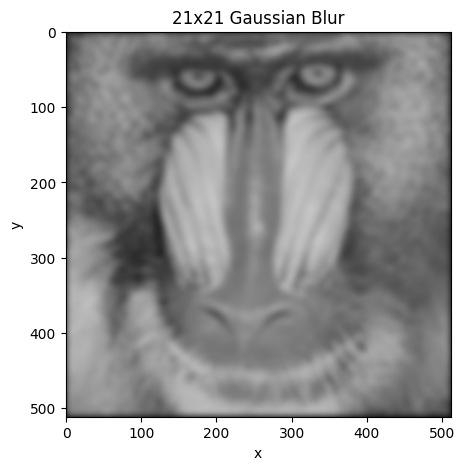

In [18]:
img = cv.imread(folder_path + "/mandrill.tiff")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])

kernel_emboss = np.array([[-2, -1, 0],
                          [-1, 1, 1],
                          [0, 1, 2]])

kernel_sobel_left = np.array([[1, 0, -1],
                              [2, 0, -2],
                              [1, 0, -1]])

kernel_canny = np.array([[-1, -1, -1],
                         [-1,  8, -1],
                         [-1, -1, -1]])

hasil_sharpen = convolution2d(img_gray, kernel_sharpen, 1, 2)
hasil_emboss = convolution2d(img_gray, kernel_emboss, 1, 2)
hasil_sobel_left = convolution2d(img_gray, kernel_sobel_left, 1, 2)
hasil_canny = convolution2d(img_gray, kernel_canny, 1, 2)

kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()
hasil_gauss_21 = convolution2d(img_gray, gauss_kernel, 1, kernel_size // 2)

for hasil, judul in [
    (hasil_sharpen, "Sharpen"),
    (hasil_emboss, "Emboss"),
    (hasil_sobel_left, "Left Sobel Edge Detection"),
    (hasil_canny, "Canny Edge Detection"),
    (hasil_gauss_21, "21x21 Gaussian Blur"),
]:
  plt.figure(figsize=(5, 5))
  plt.imshow(hasil, cmap="gray", vmin=0, vmax=255)
  plt.title(judul)
  plt.xlabel("x")
  plt.ylabel("y")
  plt.show()

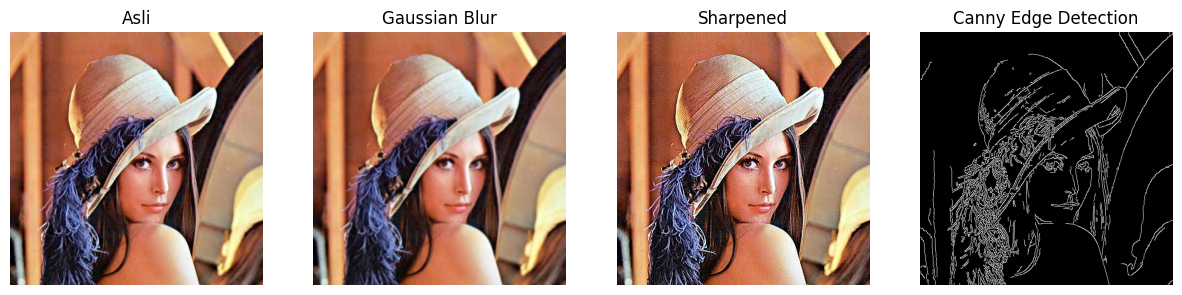

In [19]:
def show_side_by_side(images, titles, figsize=(15, 5)):
  plt.figure(figsize=figsize)
  for i, (im, title) in enumerate(zip(images, titles)):
    plt.subplot(1, len(images), i + 1)
    if len(im.shape) == 2:
      plt.imshow(im, cmap="gray")
    else:
      plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
  plt.show()


img = cv.imread(folder_path + "/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)

show_side_by_side(
    [img, blur, sharpened, edges],
    ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"],
)

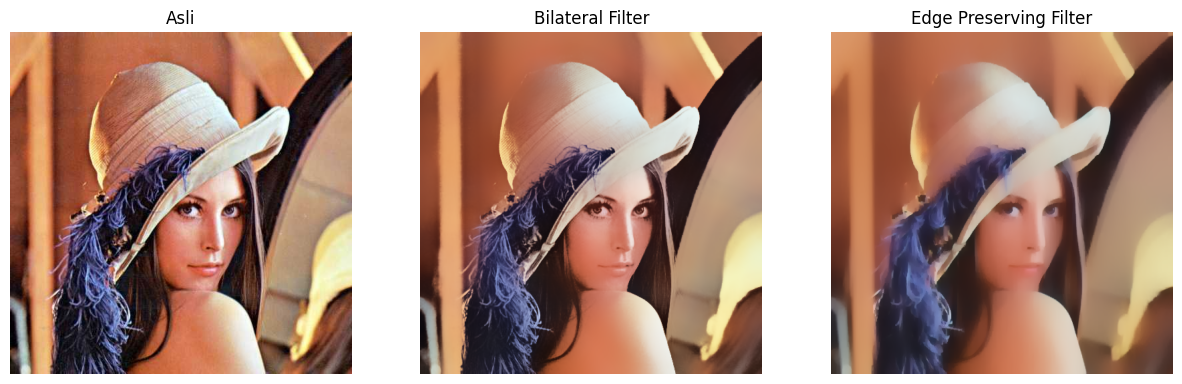

In [20]:
img = cv.imread(folder_path + "/lena.jpg")

bilateral = cv.bilateralFilter(img, 50, 100, 100)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side(
    [img, bilateral, edge_preserve],
    ["Asli", "Bilateral Filter", "Edge Preserving Filter"],
)

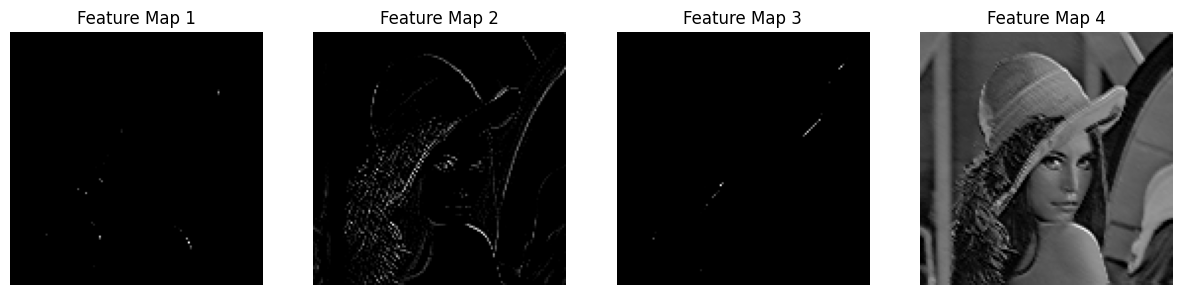

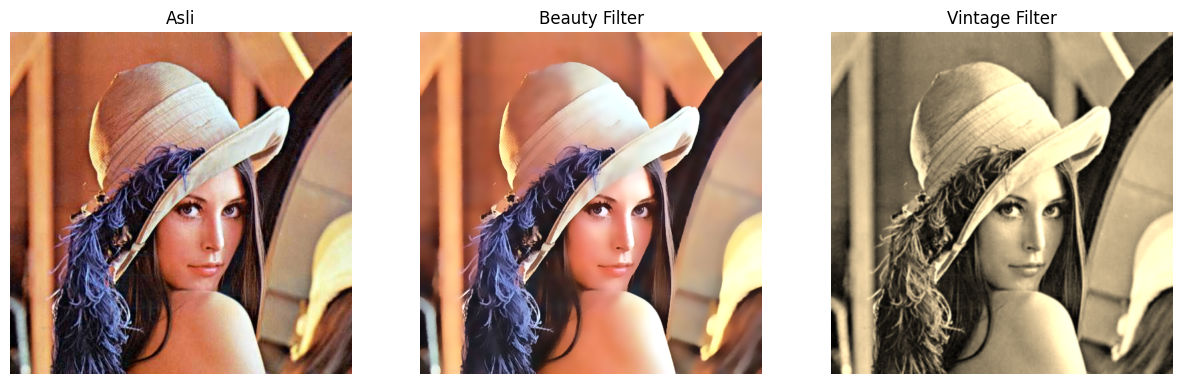

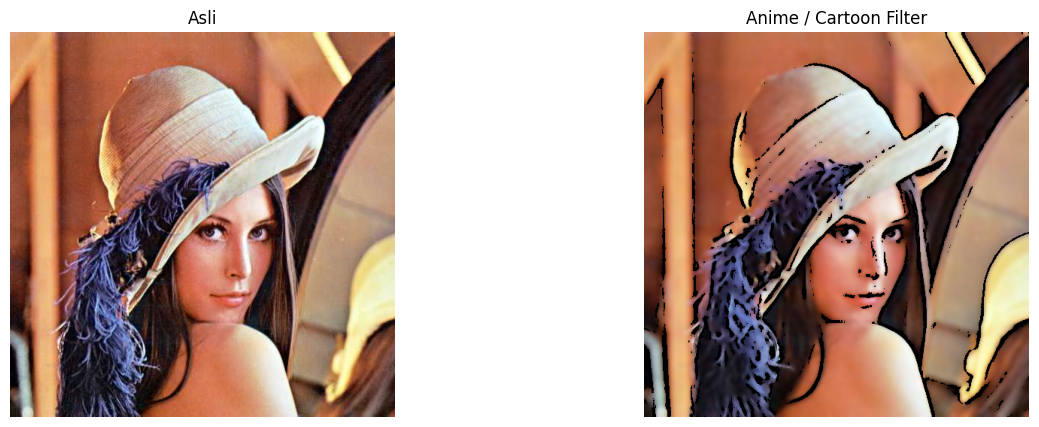

In [23]:
img = cv.imread(folder_path + "/lena.jpg")

gray_exp3 = (
    cv.resize(cv.cvtColor(img, cv.COLOR_BGR2GRAY), (128, 128)).astype(
        np.float32
    )
    / 255.0
)
feature_maps = []
for _ in range(4):
  kernel_rand = np.random.randn(3, 3) * 0.5
  act = np.maximum(0, cv.filter2D(gray_exp3, -1, kernel_rand))
  act_vis = cv.normalize(act, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
  feature_maps.append(act_vis)

show_side_by_side(
    feature_maps,
    ["Feature Map 1", "Feature Map 2", "Feature Map 3", "Feature Map 4"],
)

beauty_smooth = cv.bilateralFilter(img, 15, 75, 75)
beauty_bright = cv.convertScaleAbs(beauty_smooth, alpha=1.05, beta=10)
beauty_out = cv.addWeighted(
    beauty_bright, 0.85, cv.filter2D(beauty_bright, -1, sharpen_kernel), 0.15, 0
)

sepia_kernel = np.array(
    [[0.272, 0.534, 0.131], [0.349, 0.686, 0.168], [0.393, 0.769, 0.189]],
    dtype=np.float32,
)
vintage_sepia = cv.clip(cv.transform(img, sepia_kernel), 0, 255).astype(
    np.uint8
) if hasattr(cv, "clip") else np.clip(
    cv.transform(img, sepia_kernel), 0, 255
).astype(np.uint8)
vintage_out = cv.GaussianBlur(vintage_sepia, (3, 3), 0)

show_side_by_side(
    [img, beauty_out, vintage_out],
    ["Asli", "Beauty Filter", "Vintage Filter"],
)

gray_exp5 = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
blur_exp5 = cv.medianBlur(gray_exp5, 7)
edges_exp5 = cv.adaptiveThreshold(
    blur_exp5, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9
)
color_exp5 = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)
cartoon_out = cv.bitwise_and(color_exp5, color_exp5, mask=edges_exp5)

show_side_by_side(
    [img, cartoon_out],
    ["Asli", "Anime / Cartoon Filter"],
)

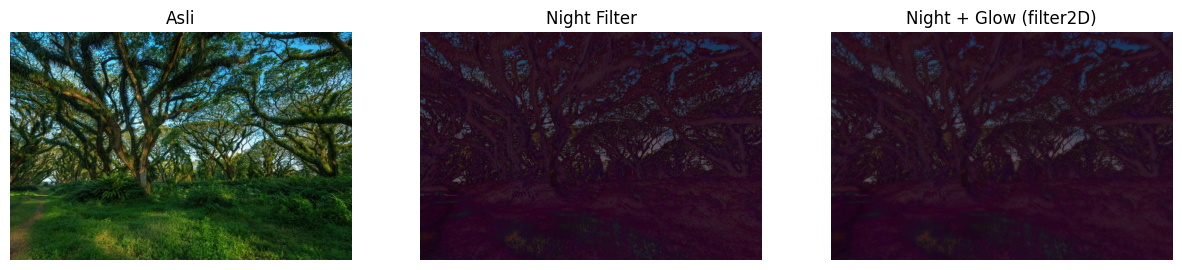

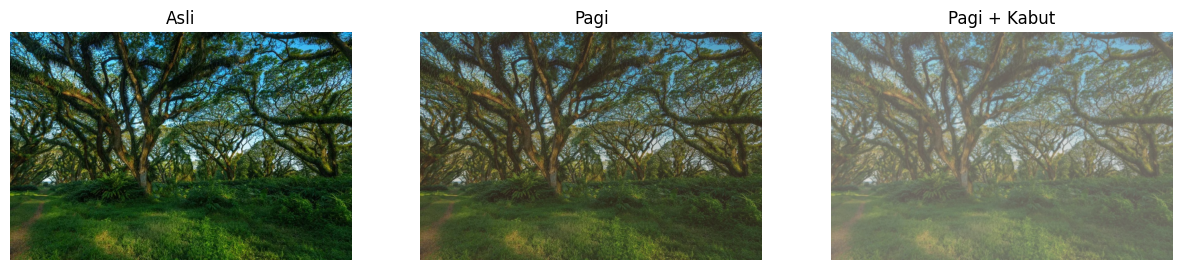

In [24]:
img = cv.imread(folder_path + "/djawatan.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Experiment 6: Night Filter & Night Glow
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)
blue_tint = np.full_like(night, (50, 0, 100))
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side(
    [img, night, night_glow],
    ["Asli", "Night Filter", "Night + Glow (filter2D)"],
)

# Experiment 7: Morning + Fog (Pagi dan Kabut)
alpha = 0.9
beta = 20
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

warm_tint = np.full_like(soft, (40, 70, 120))
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

kernel_fog = cv.getGaussianKernel(3, 3)
kernel_fog = kernel_fog @ kernel_fog.T
kabut = cv.filter2D(pagi, -1, kernel_fog)

white_layer = np.full_like(pagi, 255)
pagi_kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side(
    [img, pagi, pagi_kabut],
    ["Asli", "Pagi", "Pagi + Kabut"],
)

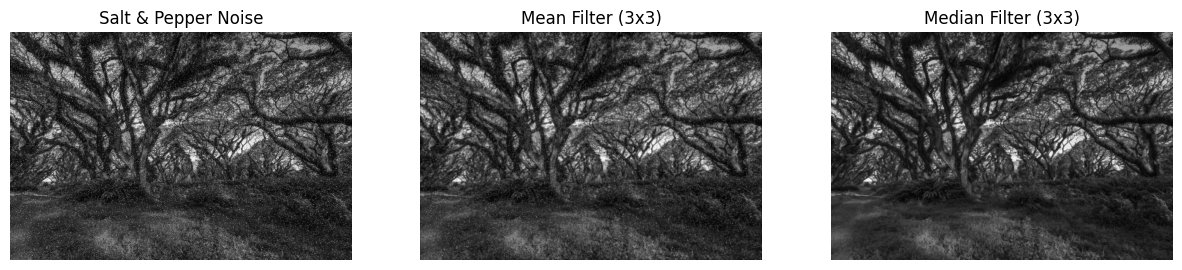

In [ ]:
# --- Task 1: Mean Filter vs Median Filter pada Salt & Pepper Noise ---
def add_salt_and_pepper(gray_img, prob=0.05, seed=42):
  rng = np.random.default_rng(seed)
  noisy = gray_img.copy()
  rand_val = rng.random(gray_img.shape)
  noisy[rand_val < prob / 2] = 0
  noisy[rand_val > 1 - prob / 2] = 255
  return noisy


img_gray_sp = add_salt_and_pepper(img_gray, prob=0.05)
mean_3x3 = convolution2d(img_gray_sp, np.ones((3, 3)) / 9.0, stride=1, padding=1)
median_3x3 = cv.medianBlur(img_gray_sp, 3)

show_side_by_side(
    [img_gray_sp, mean_3x3, median_3x3],
    ["Salt & Pepper Noise", "Mean Filter (3x3)", "Median Filter (3x3)"],
)

# --- Task 2: Kernel Sharpening 3x3 vs 5x5 ---
blur_light = cv.GaussianBlur(img_gray, (3, 3), 0.8)
blur_medium = cv.GaussianBlur(img_gray, (7, 7), 1.5)

kernel_sharp_3 = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float64)
kernel_sharp_5 = -np.ones((5, 5), dtype=np.float64)
kernel_sharp_5[2, 2] = 25.0

sharp_3_light = convolution2d(blur_light, kernel_sharp_3, stride=1, padding=1)
sharp_5_light = convolution2d(blur_light, kernel_sharp_5, stride=1, padding=2)

sharp_3_med = convolution2d(blur_medium, kernel_sharp_3, stride=1, padding=1)
sharp_5_med = convolution2d(blur_medium, kernel_sharp_5, stride=1, padding=2)

show_side_by_side(
    [blur_light, sharp_3_light, sharp_5_light],
    ["Light Blur", "Sharpen 3x3", "Sharpen 5x5"],
)
show_side_by_side(
    [blur_medium, sharp_3_med, sharp_5_med],
    ["Medium Blur", "Sharpen 3x3", "Sharpen 5x5"],
)

# --- Task 3: Fungsi cartoon(image) ---
def cartoon(image):
  color_flat = cv.bilateralFilter(image, d=9, sigmaColor=150, sigmaSpace=150)
  gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
  gray_blur = cv.medianBlur(gray, 7)
  edges = cv.adaptiveThreshold(
      gray_blur,
      255,
      cv.ADAPTIVE_THRESH_MEAN_C,
      cv.THRESH_BINARY,
      9,
      9,
  )
  edges_3ch = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
  return cv.bitwise_and(color_flat, edges_3ch)


img_cartoon_src = cv.imread(folder_path + "/lena.jpg")
img_cartoon_out = cartoon(img_cartoon_src)

show_side_by_side(
    [img_cartoon_src, img_cartoon_out],
    ["Original Image", "Cartoon Filter"],
)